# Binary Classification - Merged Dataset

## Goal
Train a **binary TFLite model** (Cancer vs Non-cancer) using a **merged dataset** from:
- `oral_cavity_binary_dataset` (cancer / non-cancer folders)
- `oral_cavity_5class_dataset` mapped to binary:
  - Cancer = OCA + OPMD
  - Non-cancer = Benign + Healthy
  - **Unknown is excluded entirely**

## Baseline Reference
- Best TFLite 5-class model: 69.66% accuracy
- This notebook aims to match or beat that with a simpler binary model on merged data.

## Training Setup (Two-Phase Transfer Learning)
- **Phase 1**: Frozen MobileNetV3Large backbone, train head only (Adam lr=1e-3, 15 epochs)
- **Phase 2**: Fine-tune top backbone layers (Adam lr=1e-5, early stopping)
- Class weights for slight imbalance; augmentation: flip, brightness, contrast, rotation, zoom
- Batch size 32, early stopping patience=5

## Where Best Models Are Saved
Each run creates a timestamped folder under `results/binary_merged/run_YYYYMMDD_HHMMSS/`:
- **Keras (best by val_loss)**: `.../models/binary_model.keras`
- **TFLite (dynamic range)**: `.../tflite/binary_merged_dynamic.tflite`
- **TFLite (float16)**: `.../tflite/binary_merged_float16.tflite`
- Plots and evaluation JSON are in the same run folder.

In [1]:
# Cell 1: Config and Setup

import os
import json
import random
import shutil
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm

# M1 MacBook Pro optimizations
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=false'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.config.optimizer.set_jit(False)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

# Check GPU
gpus = tf.config.list_physical_devices('GPU')
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(gpus) > 0}")
if gpus:
    print(f"GPU devices: {gpus}")

# Configuration - matches best TFLite model
CONFIG = {
    # Source data paths
    'data_dir_binary': os.path.expanduser('~/dev/oral_cavity_binary_dataset'),
    'data_dir_5class': os.path.expanduser('~/dev/oral_cavity_5class_dataset'),
    
    # Model config - EXACT match to best TFLite model
    'image_size': (224, 224),
    'batch_size': 32,
    'learning_rate': 1e-4,
    'epochs': 30,
    'early_stopping_patience': 5,
    'dropout_rate': 0.2,
    
    # Train/val/test split ratios (for binary dataset which has no splits)
    'val_split': 0.15,
    'test_split': 0.15,
    
    # Agent-tunable (overridden by agent_run_config.json when present)
    'use_class_weights': True,
    'augmentation': 'full',  # 'none' | 'light' | 'full'
    'phase1_epochs': 15,
}

# Agent mode: load overrides from agent_run_config.json (written by train_binary_merged_agent.py)
AGENT_RUN = False
_agent_config_path = Path('agent_run_config.json')
if _agent_config_path.exists():
    with open(_agent_config_path) as f:
        _overrides = json.load(f)
    CONFIG.update(_overrides)
    AGENT_RUN = True
    print(f"[Agent mode] Loaded overrides: {list(_overrides.keys())}")

# Output directory
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
OUTPUT_DIR = Path(f'results/binary_merged/run_{timestamp}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'models').mkdir(exist_ok=True)
(OUTPUT_DIR / 'tflite').mkdir(exist_ok=True)
(OUTPUT_DIR / 'plots').mkdir(exist_ok=True)

# Save config
with open(OUTPUT_DIR / 'config.json', 'w') as f:
    json.dump(CONFIG, f, indent=2)

print(f"\nConfiguration:")
print(f"  Output directory: {OUTPUT_DIR}")
print(f"  Image size: {CONFIG['image_size']}")
print(f"  Batch size: {CONFIG['batch_size']}")
print(f"  Learning rate: {CONFIG['learning_rate']}")

TensorFlow version: 2.15.0
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[Agent mode] Loaded overrides: ['use_class_weights', 'augmentation', 'phase1_epochs']

Configuration:
  Output directory: results/binary_merged/run_20260129_181033
  Image size: (224, 224)
  Batch size: 32
  Learning rate: 0.0001


In [2]:
# Cell 2: Load and Merge Datasets

def collect_images_from_folder(folder_path, extensions=['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']):
    """Collect all image paths from a folder."""
    folder = Path(folder_path)
    images = []
    if folder.exists():
        for ext in extensions:
            images.extend([str(p) for p in folder.glob(ext)])
    return images

print("Loading and merging datasets...")
print("=" * 60)

# --- SOURCE 1: Binary Dataset ---
print("\n[1] Binary Dataset")
binary_dir = Path(CONFIG['data_dir_binary'])

binary_cancer = collect_images_from_folder(binary_dir / 'cancer')
binary_non_cancer = collect_images_from_folder(binary_dir / 'non-cancer')

print(f"    cancer/: {len(binary_cancer)} images")
print(f"    non-cancer/: {len(binary_non_cancer)} images")
print(f"    Total: {len(binary_cancer) + len(binary_non_cancer)} images")

# --- SOURCE 2: 5-Class Dataset (mapped to binary, excluding Unknown) ---
print("\n[2] 5-Class Dataset (mapped to binary, excluding Unknown)")
five_class_dir = Path(CONFIG['data_dir_5class'])

# Collect from all splits (train, val, test)
five_class_cancer = []  # OCA + OPMD
five_class_non_cancer = []  # Benign + Healthy

for split in ['train', 'val', 'test']:
    split_dir = five_class_dir / split
    if split_dir.exists():
        # Cancer classes
        for cancer_class in ['OCA', 'OPMD']:
            imgs = collect_images_from_folder(split_dir / cancer_class)
            five_class_cancer.extend(imgs)
            print(f"    {split}/{cancer_class}: {len(imgs)} images")
        
        # Non-cancer classes
        for non_cancer_class in ['Benign', 'Healthy']:
            imgs = collect_images_from_folder(split_dir / non_cancer_class)
            five_class_non_cancer.extend(imgs)
            print(f"    {split}/{non_cancer_class}: {len(imgs)} images")

print(f"\n    5-class Cancer (OCA+OPMD): {len(five_class_cancer)} images")
print(f"    5-class Non-cancer (Benign+Healthy): {len(five_class_non_cancer)} images")

# --- MERGE ---
print("\n[3] Merged Dataset")
print("-" * 40)

all_cancer = binary_cancer + five_class_cancer
all_non_cancer = binary_non_cancer + five_class_non_cancer

# Remove duplicates (in case same images exist in both datasets)
all_cancer = list(set(all_cancer))
all_non_cancer = list(set(all_non_cancer))

print(f"    CANCER (merged): {len(all_cancer)} images")
print(f"        From binary dataset: {len(binary_cancer)}")
print(f"        From 5-class (OCA+OPMD): {len(five_class_cancer)}")
print(f"        After dedup: {len(all_cancer)}")

print(f"\n    NON-CANCER (merged): {len(all_non_cancer)} images")
print(f"        From binary dataset: {len(binary_non_cancer)}")
print(f"        From 5-class (Benign+Healthy): {len(five_class_non_cancer)}")
print(f"        After dedup: {len(all_non_cancer)}")

total_images = len(all_cancer) + len(all_non_cancer)
print(f"\n    TOTAL MERGED: {total_images} images")
print(f"    Class balance: Cancer {len(all_cancer)/total_images*100:.1f}% / Non-cancer {len(all_non_cancer)/total_images*100:.1f}%")

Loading and merging datasets...

[1] Binary Dataset
    cancer/: 884 images
    non-cancer/: 750 images
    Total: 1634 images

[2] 5-Class Dataset (mapped to binary, excluding Unknown)
    train/OCA: 216 images
    train/OPMD: 975 images
    train/Benign: 656 images
    train/Healthy: 510 images
    val/OCA: 35 images
    val/OPMD: 209 images
    val/Benign: 128 images
    val/Healthy: 109 images
    test/OCA: 36 images
    test/OPMD: 209 images
    test/Benign: 129 images
    test/Healthy: 110 images

    5-class Cancer (OCA+OPMD): 1680 images
    5-class Non-cancer (Benign+Healthy): 1642 images

[3] Merged Dataset
----------------------------------------
    CANCER (merged): 2564 images
        From binary dataset: 884
        From 5-class (OCA+OPMD): 1680
        After dedup: 2564

    NON-CANCER (merged): 2392 images
        From binary dataset: 750
        From 5-class (Benign+Healthy): 1642
        After dedup: 2392

    TOTAL MERGED: 4956 images
    Class balance: Cancer 51.7% 

In [3]:
# Cell 3: Create Train/Val/Test Splits

print("Creating train/val/test splits...")
print("=" * 60)

# Combine all images with labels
all_paths = all_cancer + all_non_cancer
all_labels = [1] * len(all_cancer) + [0] * len(all_non_cancer)  # 1=cancer, 0=non-cancer

# First split: separate test set
train_val_paths, test_paths, train_val_labels, test_labels = train_test_split(
    all_paths, all_labels,
    test_size=CONFIG['test_split'],
    random_state=SEED,
    stratify=all_labels
)

# Second split: separate validation from training
val_ratio_adjusted = CONFIG['val_split'] / (1 - CONFIG['test_split'])  # Adjust ratio
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_val_paths, train_val_labels,
    test_size=val_ratio_adjusted,
    random_state=SEED,
    stratify=train_val_labels
)

print(f"\nSplit Summary:")
print(f"  Train: {len(train_paths)} images")
print(f"      Cancer: {sum(train_labels)} ({sum(train_labels)/len(train_labels)*100:.1f}%)")
print(f"      Non-cancer: {len(train_labels) - sum(train_labels)} ({(len(train_labels) - sum(train_labels))/len(train_labels)*100:.1f}%)")

print(f"\n  Validation: {len(val_paths)} images")
print(f"      Cancer: {sum(val_labels)} ({sum(val_labels)/len(val_labels)*100:.1f}%)")
print(f"      Non-cancer: {len(val_labels) - sum(val_labels)} ({(len(val_labels) - sum(val_labels))/len(val_labels)*100:.1f}%)")

print(f"\n  Test: {len(test_paths)} images")
print(f"      Cancer: {sum(test_labels)} ({sum(test_labels)/len(test_labels)*100:.1f}%)")
print(f"      Non-cancer: {len(test_labels) - sum(test_labels)} ({(len(test_labels) - sum(test_labels))/len(test_labels)*100:.1f}%)")

# Save split info
split_info = {
    'train_count': len(train_paths),
    'val_count': len(val_paths),
    'test_count': len(test_paths),
    'train_cancer': sum(train_labels),
    'val_cancer': sum(val_labels),
    'test_cancer': sum(test_labels),
}
with open(OUTPUT_DIR / 'split_info.json', 'w') as f:
    json.dump(split_info, f, indent=2)

Creating train/val/test splits...

Split Summary:
  Train: 3468 images
      Cancer: 1794 (51.7%)
      Non-cancer: 1674 (48.3%)

  Validation: 744 images
      Cancer: 385 (51.7%)
      Non-cancer: 359 (48.3%)

  Test: 744 images
      Cancer: 385 (51.7%)
      Non-cancer: 359 (48.3%)


In [4]:
# Cell 4: Create tf.data.Dataset Pipelines

print("Creating data pipelines...")
print("=" * 60)

AUTOTUNE = tf.data.AUTOTUNE

# First, validate all images and remove corrupted ones
print("\nValidating images (removing corrupted files)...")

def is_valid_image(path):
    """Check if a file is a valid image."""
    try:
        img_data = tf.io.read_file(path)
        # decode_image handles JPEG, PNG, GIF, BMP
        img = tf.image.decode_image(img_data, channels=3)
        return True
    except:
        return False

def validate_paths(paths, labels):
    """Remove paths to corrupted/invalid images."""
    valid_paths = []
    valid_labels = []
    invalid_count = 0
    
    for path, label in tqdm(zip(paths, labels), total=len(paths), desc="Validating"):
        if is_valid_image(path):
            valid_paths.append(path)
            valid_labels.append(label)
        else:
            invalid_count += 1
            print(f"  Invalid image: {path}")
    
    if invalid_count > 0:
        print(f"\n  Removed {invalid_count} invalid images")
    else:
        print(f"\n  All {len(paths)} images are valid")
    
    return valid_paths, valid_labels

# Validate all splits
print("\nValidating train set...")
train_paths, train_labels = validate_paths(train_paths, train_labels)
print("\nValidating val set...")
val_paths, val_labels = validate_paths(val_paths, val_labels)
print("\nValidating test set...")
test_paths, test_labels = validate_paths(test_paths, test_labels)

print(f"\nAfter validation:")
print(f"  Train: {len(train_paths)} images")
print(f"  Val: {len(val_paths)} images")
print(f"  Test: {len(test_paths)} images")

def load_and_preprocess(path, label):
    """Load and preprocess a single image."""
    img = tf.io.read_file(path)
    # Use decode_image instead of decode_jpeg to handle multiple formats
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])  # Required after decode_image
    img = tf.image.resize(img, CONFIG['image_size'])
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.cast(label, tf.float32)

def augment(image, label):
    """Apply data augmentation. Level from CONFIG['augmentation']: none | light | full."""
    aug = CONFIG.get('augmentation', 'full')
    # Random horizontal flip (always)
    image = tf.image.random_flip_left_right(image)
    # Random rotation (0, 90, 180, 270) only for 'full'
    if aug == 'full':
        k = tf.random.uniform([], 0, 4, dtype=tf.int32)
        image = tf.image.rot90(image, k=k)
    # Random brightness and contrast
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    # Zoom (light and full)
    if aug in ('light', 'full'):
        h, w = tf.shape(image)[0], tf.shape(image)[1]
        crop_factor = tf.random.uniform([], 0.85, 1.0)
        image = tf.image.central_crop(image, crop_factor)
        image = tf.image.resize(image, [h, w])
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label

def create_dataset(paths, labels, batch_size, shuffle=True, augment_data=False):
    """Create a tf.data.Dataset from paths and labels."""
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)
    
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    
    if augment_data:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    
    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    
    return ds

# Create datasets
train_ds = create_dataset(train_paths, train_labels, CONFIG['batch_size'], shuffle=True, augment_data=True)
val_ds = create_dataset(val_paths, val_labels, CONFIG['batch_size'], shuffle=False, augment_data=False)
test_ds = create_dataset(test_paths, test_labels, CONFIG['batch_size'], shuffle=False, augment_data=False)

print(f"Datasets created:")
print(f"  Train: {len(train_paths)} samples, {len(train_paths) // CONFIG['batch_size']} batches")
print(f"  Val: {len(val_paths)} samples, {len(val_paths) // CONFIG['batch_size']} batches")
print(f"  Test: {len(test_paths)} samples, {len(test_paths) // CONFIG['batch_size']} batches")

Creating data pipelines...

Validating images (removing corrupted files)...

Validating train set...


Validating:   0%|                                         | 0/3468 [00:00<?, ?it/s]

Validating:   0%|                                 | 3/3468 [00:00<02:54, 19.89it/s]

Validating:   0%|                                 | 8/3468 [00:00<01:53, 30.48it/s]

Validating:   0%|                                | 12/3468 [00:00<02:24, 23.89it/s]

...

Validating:  99%|███████████████████████████████▊| 740/744 [00:34<00:00, 24.91it/s]

Validating: 100%|███████████████████████████████▉| 743/744 [00:34<00:00, 23.88it/s]

Validating: 100%|████████████████████████████████| 744/744 [00:34<00:00, 21.65it/s]

  Invalid image: /Users/alokdwivedi/dev/oral_cavity_binary_dataset/cancer/426.jpeg

  Removed 8 invalid images

After validation:
  Train: 3442 images
  Val: 738 images
  Test: 736 images


Datasets created:
  Train: 3442 samples, 107 batches
  Val: 738 samples, 23 batches
  Test: 736 samples, 23 batches


In [5]:
# Cell 5: Build Model (MobileNetV3Large - Two-Phase Transfer Learning)
# FIX: Proper transfer learning with frozen backbone first, then fine-tuning

print("Building Binary Classification Model...")
print("=" * 60)

# Load pre-trained MobileNetV3Large as a separate variable (for fine-tuning later)
base_model = MobileNetV3Large(
    weights='imagenet',
    include_top=False,
    input_shape=(*CONFIG['image_size'], 3),
    alpha=1.0,
    minimalistic=False
)

# CRITICAL FIX: Freeze the base model for Phase 1
# Without this, random head gradients destroy pretrained features
base_model.trainable = False

# Build classification head
inputs = layers.Input(shape=(*CONFIG['image_size'], 3))
x = base_model(inputs, training=False)  # Always use inference mode for frozen backbone
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(1280, activation='relu')(x)
x = layers.Dropout(CONFIG['dropout_rate'])(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

model = Model(inputs, outputs)

# Compile for Phase 1 (frozen backbone) - use HIGHER LR for head training
# 1e-3 is standard for training new layers on frozen backbone
model.compile(
    optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Count trainable vs non-trainable params
trainable_count = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
non_trainable_count = sum([tf.keras.backend.count_params(w) for w in model.non_trainable_weights])

print(f"\nModel Summary (Phase 1 - Frozen Backbone):")
print(f"  Architecture: MobileNetV3Large + Dense(1280) + Dropout({CONFIG['dropout_rate']}) + Dense(1, sigmoid)")
print(f"  Total Parameters: {model.count_params():,}")
print(f"  Trainable Parameters: {trainable_count:,} (head only)")
print(f"  Non-trainable Parameters: {non_trainable_count:,} (frozen backbone)")
print(f"  Optimizer: Adam (lr=1e-3)")
print(f"  Loss: binary_crossentropy")

Building Binary Classification Model...



Model Summary (Phase 1 - Frozen Backbone):
  Architecture: MobileNetV3Large + Dense(1280) + Dropout(0.2) + Dense(1, sigmoid)
  Total Parameters: 4,227,713
  Trainable Parameters: 1,231,361 (head only)
  Non-trainable Parameters: 2,996,352 (frozen backbone)
  Optimizer: Adam (lr=1e-3)
  Loss: binary_crossentropy


In [6]:
# Cell 6: Train Model (Two-Phase Transfer Learning)

# Class weights (optional, from CONFIG for agent runs)
CLASS_WEIGHT = None
if CONFIG.get('use_class_weights', True):
    classes = np.unique(train_labels)
    weights = compute_class_weight('balanced', classes=classes, y=train_labels)
    CLASS_WEIGHT = dict(zip(classes, weights))
    print("Class weights (0=non-cancer, 1=cancer):", CLASS_WEIGHT)
else:
    print("Class weights: disabled")

print("=" * 60)
print("PHASE 1: Training Classification Head (Frozen Backbone)")
print("=" * 60)

# Model path
model_path = str(OUTPUT_DIR / 'models' / 'binary_model.keras')

# Phase 1 Callbacks
phase1_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        model_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

# Phase 1: Train head with frozen backbone (epochs from CONFIG, optional class_weight)
phase1_epochs = CONFIG.get('phase1_epochs', 15)
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=phase1_epochs,
    class_weight=CLASS_WEIGHT,
    callbacks=phase1_callbacks,
    verbose=1
)

print(f"\nPhase 1 complete!")
print(f"  Best val_loss: {min(history1.history['val_loss']):.4f}")
print(f"  Best val_accuracy: {max(history1.history['val_accuracy']):.4f}")

# ============================================================
# PHASE 2: Fine-tune top backbone layers
# ============================================================
print("\n" + "=" * 60)
print("PHASE 2: Fine-Tuning Top Backbone Layers")
print("=" * 60)

# Unfreeze top layers of the backbone
base_model.trainable = True

# Freeze bottom layers, keep top ~30% trainable
# MobileNetV3Large has ~150 layers, unfreeze top ~50
fine_tune_from = 100
for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

# Recompile with LOWER learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=1e-5),  # Very low LR for fine-tuning
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Count updated trainable params
trainable_count = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
non_trainable_count = sum([tf.keras.backend.count_params(w) for w in model.non_trainable_weights])
print(f"\nFine-tuning from layer {fine_tune_from}")
print(f"  Trainable Parameters: {trainable_count:,}")
print(f"  Non-trainable Parameters: {non_trainable_count:,}")
print(f"  Optimizer: Adam (lr=1e-5)")

# Phase 2 Callbacks
phase2_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=CONFIG['early_stopping_patience'],
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        model_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# Phase 2: Fine-tune with more epochs
total_epochs = CONFIG['epochs']
initial_epochs = len(history1.history['loss'])

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=initial_epochs,
    class_weight=CLASS_WEIGHT,
    callbacks=phase2_callbacks,
    verbose=1
)

# Combine histories
history = {
    'loss': history1.history['loss'] + history2.history['loss'],
    'val_loss': history1.history['val_loss'] + history2.history['val_loss'],
    'accuracy': history1.history['accuracy'] + history2.history['accuracy'],
    'val_accuracy': history1.history['val_accuracy'] + history2.history['val_accuracy'],
}

# Save combined training history
with open(OUTPUT_DIR / 'training_history.json', 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.items()}, f, indent=2)

print(f"\n" + "=" * 60)
print("Training Complete!")
print("=" * 60)
print(f"  Phase 1 epochs: {initial_epochs}")
print(f"  Phase 2 epochs: {len(history2.history['loss'])}")
print(f"  Best val_loss: {min(history['val_loss']):.4f}")
print(f"  Best val_accuracy: {max(history['val_accuracy']):.4f}")
print(f"  Model saved to: {model_path}")

Class weights (0=non-cancer, 1=cancer): {0: 1.0317745803357314, 1: 0.9701240135287486}
PHASE 1: Training Classification Head (Frozen Backbone)
Epoch 1/20


  1/108 [..............................] - ETA: 4:50 - loss: 1.0772 - accuracy: 0.4375

  2/108 [..............................] - ETA: 7s - loss: 0.8931 - accuracy: 0.4844  

  3/108 [..............................] - ETA: 6s - loss: 0.9168 - accuracy: 0.4792

  4/108 [>.............................] - ETA: 6s - loss: 0.9197 - accuracy: 0.4531

...

107/108 [============================>.] - ETA: 0s - loss: 0.6635 - accuracy: 0.5932

108/108 [==============================] - ETA: 0s - loss: 0.6634 - accuracy: 0.5941


Epoch 30: val_loss did not improve from 0.67289


108/108 [==============================] - 32s 294ms/step - loss: 0.6634 - accuracy: 0.5941 - val_loss: 0.6741 - val_accuracy: 0.5650 - lr: 5.0000e-06



Training Complete!
  Phase 1 epochs: 17
  Phase 2 epochs: 13
  Best val_loss: 0.6729
  Best val_accuracy: 0.5949
  Model saved to: results/binary_merged/run_20260129_181033/models/binary_model.keras


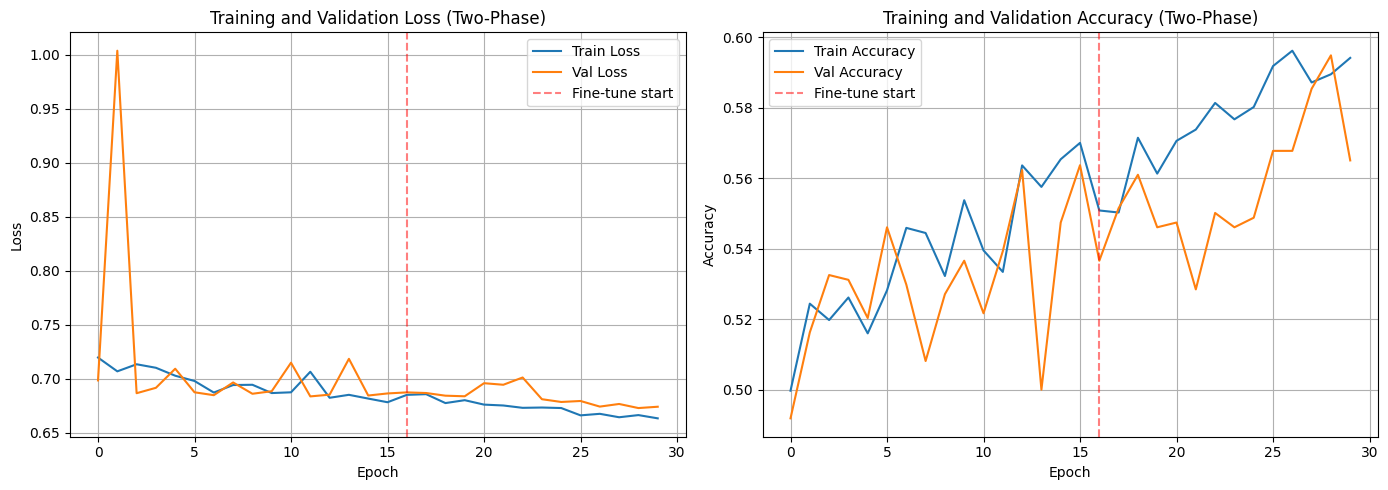

Training curves saved to: results/binary_merged/run_20260129_181033/plots/training_curves.png


In [7]:
# Cell 7: Plot Training History (Two-Phase)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Get phase boundary for visualization
phase1_epochs = len(history1.history['loss'])

# Loss plot
axes[0].plot(history['loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].axvline(x=phase1_epochs-1, color='red', linestyle='--', alpha=0.5, label='Fine-tune start')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss (Two-Phase)')
axes[0].legend()
axes[0].grid(True)

# Accuracy plot
axes[1].plot(history['accuracy'], label='Train Accuracy')
axes[1].plot(history['val_accuracy'], label='Val Accuracy')
axes[1].axvline(x=phase1_epochs-1, color='red', linestyle='--', alpha=0.5, label='Fine-tune start')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy (Two-Phase)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plots' / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Training curves saved to: {OUTPUT_DIR / 'plots' / 'training_curves.png'}")

In [8]:
# Cell 8: Evaluate on Test Set

print("Evaluating on Test Set...")
print("=" * 60)

# Load best model
best_model = keras.models.load_model(model_path)

# Get predictions
all_preds = []
all_probs = []
all_true = []

for images, labels in tqdm(test_ds, desc='Evaluating'):
    probs = best_model.predict(images, verbose=0).flatten()
    preds = (probs >= 0.5).astype(int)
    
    all_probs.extend(probs.tolist())
    all_preds.extend(preds.tolist())
    all_true.extend(labels.numpy().tolist())

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_true = np.array(all_true)

# Calculate metrics
accuracy = float(np.mean(all_preds == all_true))

print(f"\n" + "=" * 60)
print(f"RESULTS: Binary Classification (Merged Dataset)")
print(f"=" * 60)

print(f"\nOverall Accuracy: {accuracy*100:.2f}%")
print(f"\nDataset Size: {len(all_true)} test samples")
print(f"  Cancer: {sum(all_true)} ({sum(all_true)/len(all_true)*100:.1f}%)")
print(f"  Non-cancer: {len(all_true) - sum(all_true)} ({(len(all_true) - sum(all_true))/len(all_true)*100:.1f}%)")

# Per-class metrics
print(f"\nPer-Class Accuracy:")
cancer_mask = all_true == 1
non_cancer_mask = all_true == 0
cancer_acc = np.mean(all_preds[cancer_mask] == all_true[cancer_mask])
non_cancer_acc = np.mean(all_preds[non_cancer_mask] == all_true[non_cancer_mask])
print(f"  Cancer: {cancer_acc*100:.2f}% (Sensitivity/Recall)")
print(f"  Non-cancer: {non_cancer_acc*100:.2f}% (Specificity)")

# Confusion Matrix
print(f"\nConfusion Matrix:")
cm = confusion_matrix(all_true, all_preds)
print(f"                  Predicted")
print(f"                  Non-cancer  Cancer")
print(f"  Actual Non-cancer:  {cm[0,0]:>6}    {cm[0,1]:>6}")
print(f"  Actual Cancer:      {cm[1,0]:>6}    {cm[1,1]:>6}")

# Classification report
print(f"\nClassification Report:")
print(classification_report(all_true, all_preds, target_names=['Non-cancer', 'Cancer']))

# Sensitivity/Specificity at different thresholds (helps interpret cancer vs non-cancer tradeoff)
print(f"\nMetrics at different decision thresholds (prob >= threshold → Cancer):")
for thresh in [0.4, 0.5, 0.6]:
    preds_t = (all_probs >= thresh).astype(int)
    acc_t = np.mean(preds_t == all_true)
    sens_t = np.mean(preds_t[cancer_mask] == all_true[cancer_mask])
    spec_t = np.mean(preds_t[non_cancer_mask] == all_true[non_cancer_mask])
    print(f"  Threshold {thresh}: Accuracy={acc_t*100:.1f}%  Sensitivity={sens_t*100:.1f}%  Specificity={spec_t*100:.1f}%")

# Confidence distribution
print(f"\nConfidence Distribution:")
print(f"  Mean probability: {all_probs.mean():.3f}")
print(f"  Min probability: {all_probs.min():.3f}")
print(f"  Max probability: {all_probs.max():.3f}")

# Save results
results = {
    'accuracy': accuracy,
    'cancer_accuracy': float(cancer_acc),
    'non_cancer_accuracy': float(non_cancer_acc),
    'test_samples': len(all_true),
    'confusion_matrix': cm.tolist(),
}
with open(OUTPUT_DIR / 'evaluation_results.json', 'w') as f:
    json.dump(results, f, indent=2)

print(f"\nResults saved to: {OUTPUT_DIR / 'evaluation_results.json'}")

# Agent mode: write single result file for train_binary_merged_agent.py to read
if AGENT_RUN:
    agent_result_path = Path('results/binary_merged/agent_result.json')
    agent_result_path.parent.mkdir(parents=True, exist_ok=True)
    agent_result = {
        'accuracy': accuracy,
        'sensitivity': float(cancer_acc),
        'specificity': float(non_cancer_acc),
        'output_dir': str(OUTPUT_DIR),
        'config_used': {k: v for k, v in CONFIG.items() if k in ('use_class_weights', 'augmentation', 'phase1_epochs')},
    }
    with open(agent_result_path, 'w') as f:
        json.dump(agent_result, f, indent=2)
    print(f"[Agent] Wrote {agent_result_path}")

Evaluating on Test Set...


Evaluating:   0%|                                           | 0/23 [00:00<?, ?it/s]

Evaluating:   4%|█▌                                 | 1/23 [00:01<00:36,  1.68s/it]

Evaluating:   9%|███                                | 2/23 [00:01<00:16,  1.30it/s]

Evaluating:  13%|████▌                              | 3/23 [00:01<00:09,  2.11it/s]

...

Evaluating:  91%|███████████████████████████████   | 21/23 [00:05<00:00,  5.20it/s]

Evaluating:  96%|████████████████████████████████▌ | 22/23 [00:05<00:00,  5.00it/s]

Evaluating: 100%|██████████████████████████████████| 23/23 [00:05<00:00,  5.53it/s]

Evaluating: 100%|██████████████████████████████████| 23/23 [00:05<00:00,  4.17it/s]


RESULTS: Binary Classification (Merged Dataset)

Overall Accuracy: 61.68%

Dataset Size: 736 test samples
  Cancer: 381.0 (51.8%)
  Non-cancer: 355.0 (48.2%)

Per-Class Accuracy:
  Cancer: 74.28% (Sensitivity/Recall)
  Non-cancer: 48.17% (Specificity)

Confusion Matrix:
                  Predicted
                  Non-cancer  Cancer
  Actual Non-cancer:     171       184
  Actual Cancer:          98       283

Classification Report:
              precision    recall  f1-score   support

  Non-cancer       0.64      0.48      0.55       355
      Cancer       0.61      0.74      0.67       381

    accuracy                           0.62       736
   macro avg       0.62      0.61      0.61       736
weighted avg       0.62      0.62      0.61       736


Metrics at different decision thresholds (prob >= threshold → Cancer):
  Threshold 0.4: Accuracy=54.8%  Sensitivity=95.8%  Specificity=10.7%
  Threshold 0.5: Accuracy=61.7%  Sensitivity=74.3%  Specificity=48.2%
  Threshold 0.6: Accur

In [9]:
# Cell 9: Convert to TFLite

print("Converting to TFLite...")
print("=" * 60)

def convert_to_tflite(model, output_path, quantization='dynamic'):
    """Convert Keras model to TFLite."""
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    
    if quantization == 'dynamic':
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    elif quantization == 'float16':
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    
    tflite_model = converter.convert()
    
    with open(output_path, 'wb') as f:
        f.write(tflite_model)
    
    size_mb = len(tflite_model) / (1024 * 1024)
    return size_mb

# Convert with dynamic quantization
tflite_path = OUTPUT_DIR / 'tflite' / 'binary_merged_dynamic.tflite'
tflite_size = convert_to_tflite(best_model, str(tflite_path), 'dynamic')

print(f"\nTFLite Model:")
print(f"  Path: {tflite_path}")
print(f"  Size: {tflite_size:.2f} MB")

# Also save float16 version
tflite_path_fp16 = OUTPUT_DIR / 'tflite' / 'binary_merged_float16.tflite'
tflite_size_fp16 = convert_to_tflite(best_model, str(tflite_path_fp16), 'float16')
print(f"\nTFLite (float16):")
print(f"  Path: {tflite_path_fp16}")
print(f"  Size: {tflite_size_fp16:.2f} MB")

Converting to TFLite...


INFO:tensorflow:Assets written to: /var/folders/7w/rpdt250519x332ww6xcspbnh0000gp/T/tmp6savdfti/assets


INFO:tensorflow:Assets written to: /var/folders/7w/rpdt250519x332ww6xcspbnh0000gp/T/tmp6savdfti/assets


Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 75, Total Ops 263, % non-converted = 28.52 %
 * 75 ARITH ops

- arith.constant:   75 occurrences  (f32: 72, i32: 3)



  (f32: 11)
  (f32: 47)
  (f32: 15)
  (f32: 2)
  (f32: 20)
  (f32: 1)
  (f32: 9)
  (f32: 17)
  (f32: 4)
  (uq_8: 59)



TFLite Model:
  Path: results/binary_merged/run_20260129_181033/tflite/binary_merged_dynamic.tflite
  Size: 4.31 MB


INFO:tensorflow:Assets written to: /var/folders/7w/rpdt250519x332ww6xcspbnh0000gp/T/tmpcvsvoy7v/assets


INFO:tensorflow:Assets written to: /var/folders/7w/rpdt250519x332ww6xcspbnh0000gp/T/tmpcvsvoy7v/assets



TFLite (float16):
  Path: results/binary_merged/run_20260129_181033/tflite/binary_merged_float16.tflite
  Size: 8.08 MB


Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 134, Total Ops 394, % non-converted = 34.01 %
 * 134 ARITH ops

- arith.constant:  134 occurrences  (f16: 131, i32: 3)



  (f32: 11)
  (f32: 47)
  (f32: 15)
  (f32: 131)
  (f32: 2)
  (f32: 20)
  (f32: 1)
  (f32: 9)
  (f32: 17)
  (f32: 4)


In [10]:
# Cell 10: Verify TFLite Model

print("Verifying TFLite Model...")
print("=" * 60)

# Load TFLite model
interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"\nTFLite Model Details:")
print(f"  Input shape: {input_details[0]['shape']}")
print(f"  Input dtype: {input_details[0]['dtype']}")
print(f"  Output shape: {output_details[0]['shape']}")
print(f"  Output dtype: {output_details[0]['dtype']}")

# Run inference on a few test samples
print(f"\nTesting TFLite inference on 5 samples...")
test_sample_paths = test_paths[:5]
test_sample_labels = test_labels[:5]

for i, (path, true_label) in enumerate(zip(test_sample_paths, test_sample_labels)):
    # Load and preprocess
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, CONFIG['image_size'])
    img = tf.cast(img, tf.float32) / 255.0
    img = tf.expand_dims(img, axis=0).numpy()
    
    # TFLite inference
    interpreter.set_tensor(input_details[0]['index'], img)
    interpreter.invoke()
    tflite_prob = interpreter.get_tensor(output_details[0]['index'])[0][0]
    tflite_pred = 1 if tflite_prob >= 0.5 else 0
    
    # Keras inference (for comparison)
    keras_prob = best_model.predict(img, verbose=0)[0][0]
    
    label_str = 'Cancer' if true_label == 1 else 'Non-cancer'
    pred_str = 'Cancer' if tflite_pred == 1 else 'Non-cancer'
    match = '✓' if tflite_pred == true_label else '✗'
    
    print(f"  [{i+1}] True: {label_str:10} | TFLite: {pred_str:10} (prob={tflite_prob:.3f}) | Keras prob={keras_prob:.3f} | {match}")

print(f"\nTFLite verification complete!")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Verifying TFLite Model...

TFLite Model Details:
  Input shape: [  1 224 224   3]
  Input dtype: <class 'numpy.float32'>
  Output shape: [1 1]
  Output dtype: <class 'numpy.float32'>

Testing TFLite inference on 5 samples...


  [1] True: Cancer     | TFLite: Cancer     (prob=0.592) | Keras prob=0.560 | ✓
  [2] True: Non-cancer | TFLite: Cancer     (prob=0.711) | Keras prob=0.574 | ✗
  [3] True: Cancer     | TFLite: Cancer     (prob=0.630) | Keras prob=0.613 | ✓


  [4] True: Non-cancer | TFLite: Cancer     (prob=0.579) | Keras prob=0.492 | ✗
  [5] True: Cancer     | TFLite: Cancer     (prob=0.621) | Keras prob=0.482 | ✓

TFLite verification complete!


In [11]:
# Cell 11: Summary

print("=" * 60)
print("BINARY CLASSIFICATION (MERGED DATASET) - SUMMARY")
print("=" * 60)

print(f"\nDataset:")
print(f"  Source 1: Binary dataset ({len(binary_cancer)} cancer + {len(binary_non_cancer)} non-cancer)")
print(f"  Source 2: 5-class dataset mapped to binary ({len(five_class_cancer)} OCA/OPMD + {len(five_class_non_cancer)} Benign/Healthy)")
print(f"  Merged total: {total_images} images")
print(f"  Train/Val/Test: {len(train_paths)}/{len(val_paths)}/{len(test_paths)}")

print(f"\nModel:")
print(f"  Architecture: MobileNetV3Large (pretrained ImageNet)")
print(f"  Parameters: {model.count_params():,}")
print(f"  TFLite size: {tflite_size:.2f} MB")

print(f"\nResults:")
print(f"  Test Accuracy: {accuracy*100:.2f}%")
print(f"  Cancer Accuracy (Sensitivity): {cancer_acc*100:.2f}%")
print(f"  Non-cancer Accuracy (Specificity): {non_cancer_acc*100:.2f}%")

print(f"\nOutput Directory: {OUTPUT_DIR}")
print(f"  Models: {OUTPUT_DIR / 'models'}")
print(f"  TFLite: {OUTPUT_DIR / 'tflite'}")
print(f"  Plots: {OUTPUT_DIR / 'plots'}")

print(f"\n" + "=" * 60)
print("DONE!")
print("=" * 60)

BINARY CLASSIFICATION (MERGED DATASET) - SUMMARY

Dataset:
  Source 1: Binary dataset (884 cancer + 750 non-cancer)
  Source 2: 5-class dataset mapped to binary (1680 OCA/OPMD + 1642 Benign/Healthy)
  Merged total: 4956 images
  Train/Val/Test: 3442/738/736

Model:
  Architecture: MobileNetV3Large (pretrained ImageNet)
  Parameters: 4,227,713
  TFLite size: 4.31 MB

Results:
  Test Accuracy: 61.68%
  Cancer Accuracy (Sensitivity): 74.28%
  Non-cancer Accuracy (Specificity): 48.17%

Output Directory: results/binary_merged/run_20260129_181033
  Models: results/binary_merged/run_20260129_181033/models
  TFLite: results/binary_merged/run_20260129_181033/tflite
  Plots: results/binary_merged/run_20260129_181033/plots

DONE!
